In [1]:
# Cellule 0 : imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
PALETTE = {"No": "#4C9F70", "Yes": "#D1495B"}   # vert = reste, rouge = part

In [3]:
# Cellule 1 : chargement

def load_data():
    """Essaie kagglehub, sinon CSV local."""
    try:
        import kagglehub, os
        path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
        return pd.read_csv(os.path.join(path, "WA_Fn-UseC_-HR-Employee-Attrition.csv"))
    except Exception as e:
        print("Kaggle indisponible, utilisation du CSV local :", e)
        return pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

df = load_data()
df.shape

Kaggle indisponible, utilisation du CSV local : No module named 'kagglehub'


(1470, 35)

Dimensions : 1470 lignes x 35 colonnes
Variables numériques : 26 | catégorielles : 9



,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Statistiques descriptives (numériques)


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


Statistiques descriptives (catégorielles)


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


Valeurs manquantes au total : 0


'Aucune valeur manquante'

Colonnes constantes (à supprimer) : ['EmployeeCount', 'Over18', 'StandardHours']

Ratio de déséquilibre : 5.2 pour 1


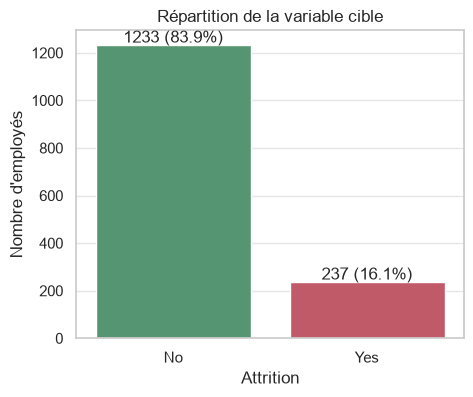

In [4]:
# Cellule 2 : stats

print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print(f"Variables numériques : {df.select_dtypes('number').shape[1]} | "
      f"catégorielles : {df.select_dtypes('object').shape[1]}\n")

display(df.head())

print("Statistiques descriptives (numériques)")
display(df.describe().T.round(2))
print("Statistiques descriptives (catégorielles)")
display(df.describe(include="object").T)

# Valeurs manquantes
manq = pd.DataFrame({"manquantes": df.isna().sum(),
                     "%": (df.isna().mean() * 100).round(2)})
print(f"Valeurs manquantes au total : {manq['manquantes'].sum()}")
display(manq[manq["manquantes"] > 0] if manq["manquantes"].sum() > 0
        else "Aucune valeur manquante")

# Colonnes inutiles (constantes)
constantes = [c for c in df.columns if df[c].nunique() == 1]
print("Colonnes constantes (à supprimer) :", constantes)

# Proportion des classes
counts = df["Attrition"].value_counts()
pct = df["Attrition"].value_counts(normalize=True) * 100
print(f"\nRatio de déséquilibre : {counts['No'] / counts['Yes']:.1f} pour 1")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Attrition", hue="Attrition", palette=PALETTE,
              order=["No", "Yes"], legend=False, ax=ax)
for i, k in enumerate(["No", "Yes"]):
    ax.text(i, counts[k] + 10, f"{counts[k]} ({pct[k]:.1f}%)", ha="center")
ax.set_title("Répartition de la variable cible")
ax.set_ylabel("Nombre d'employés")
plt.show()

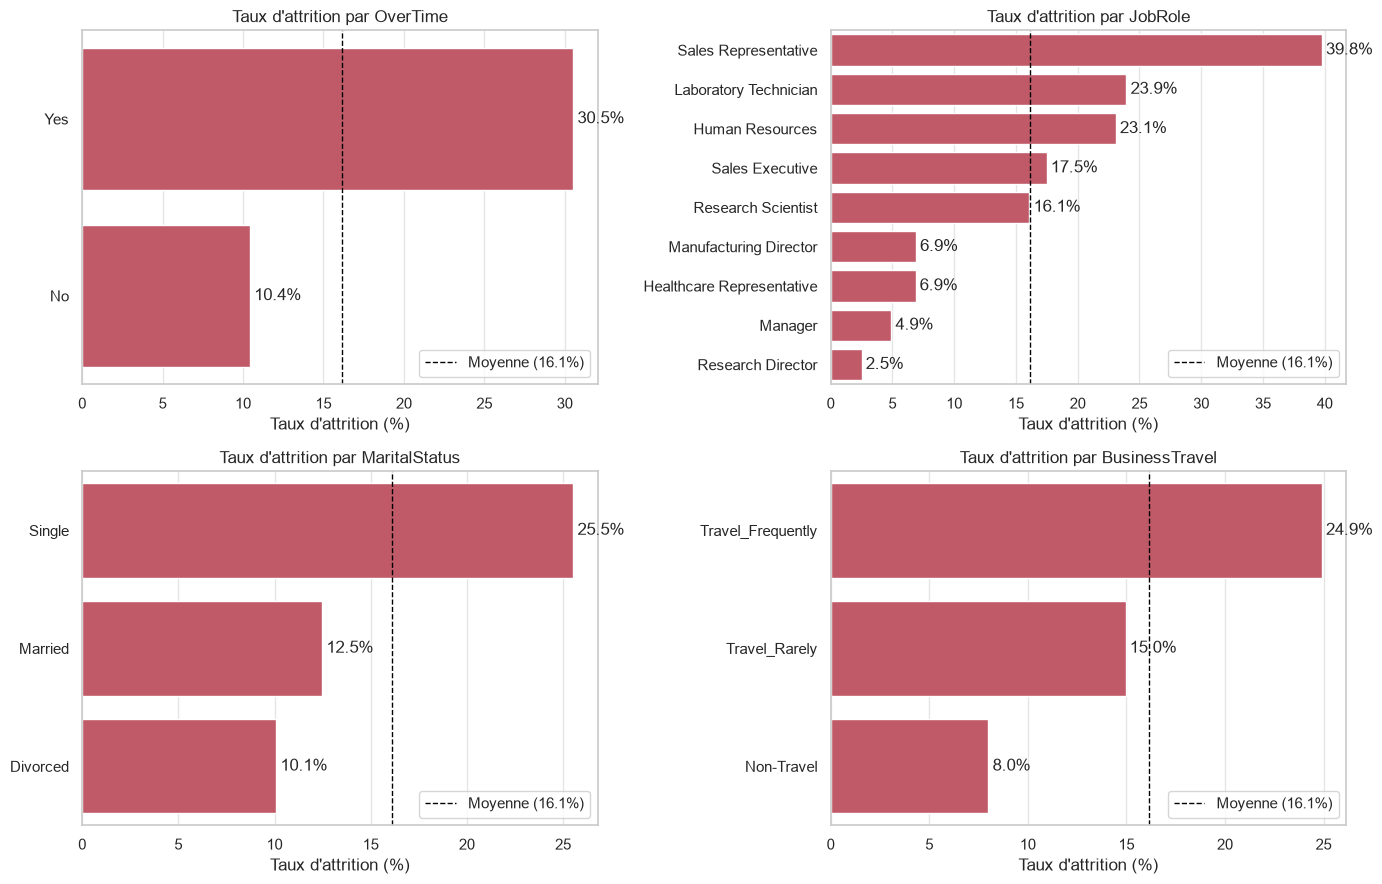

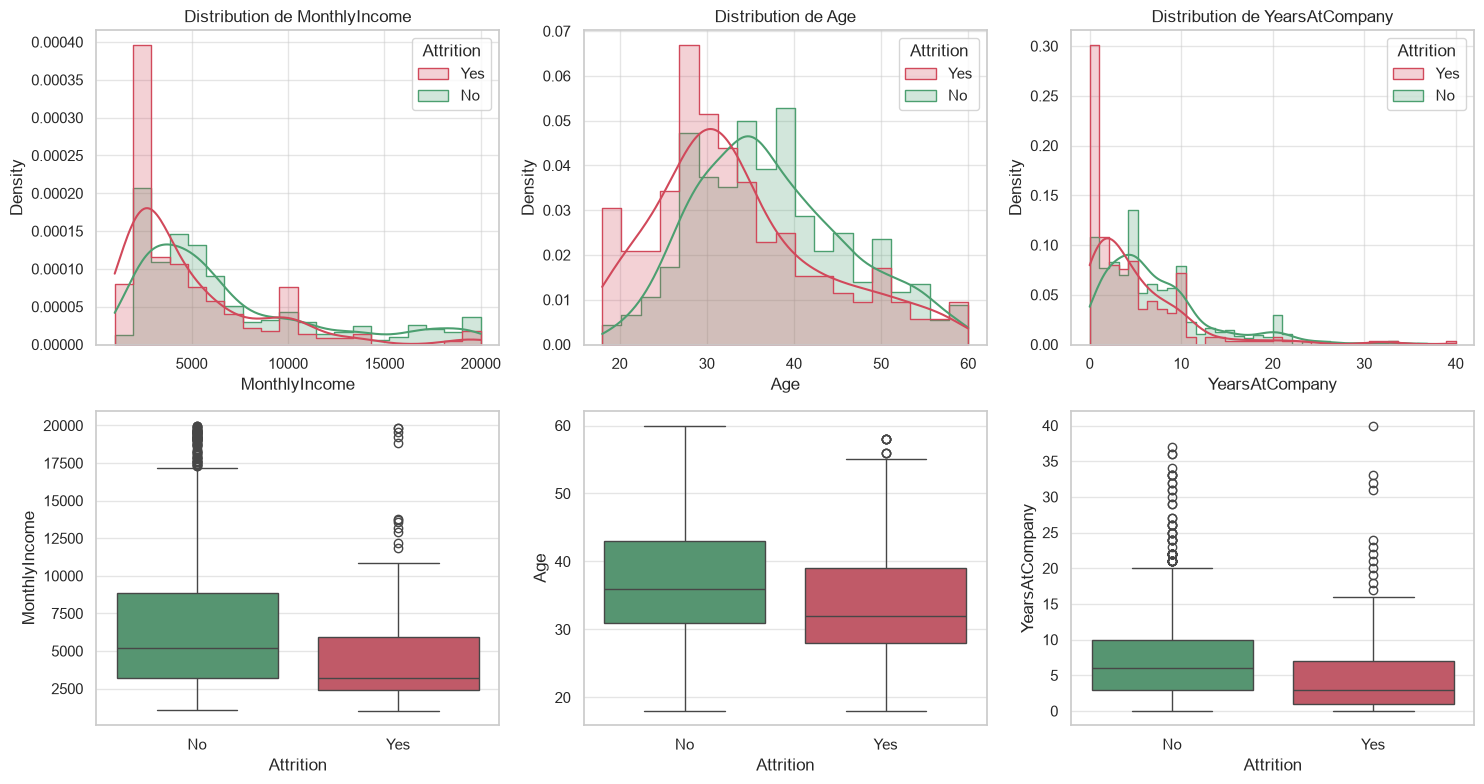

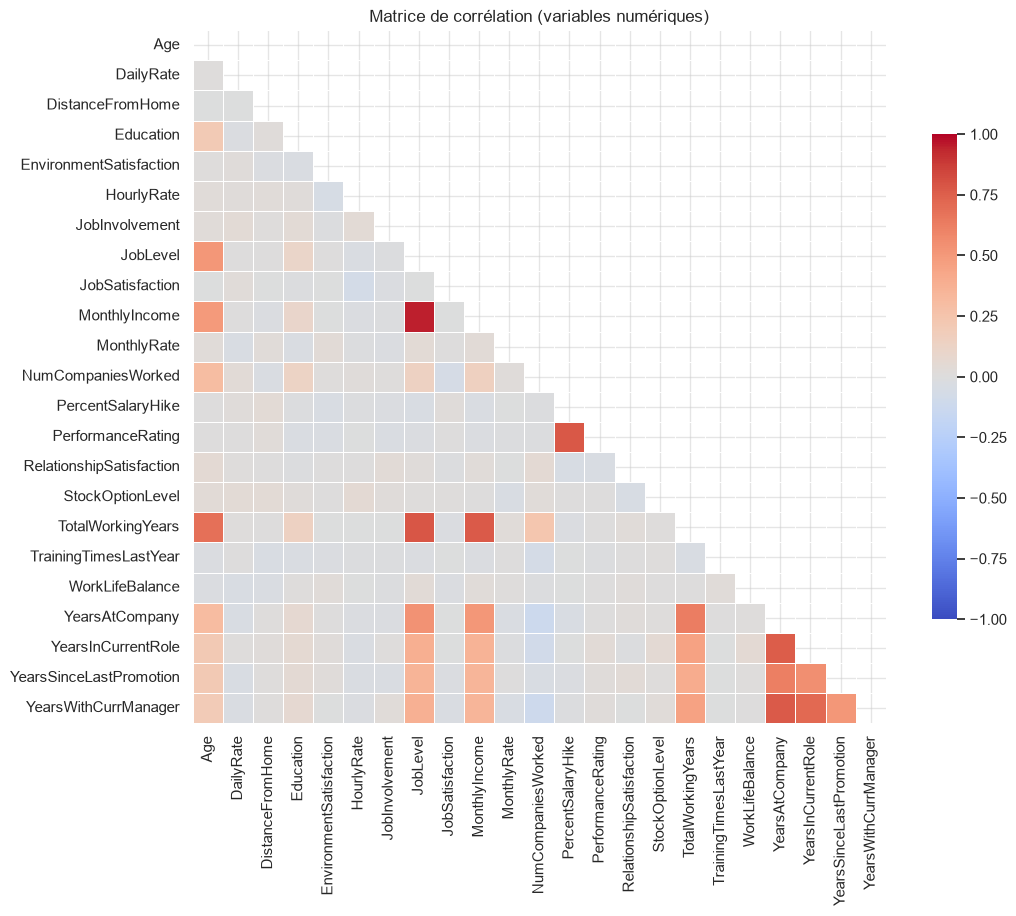

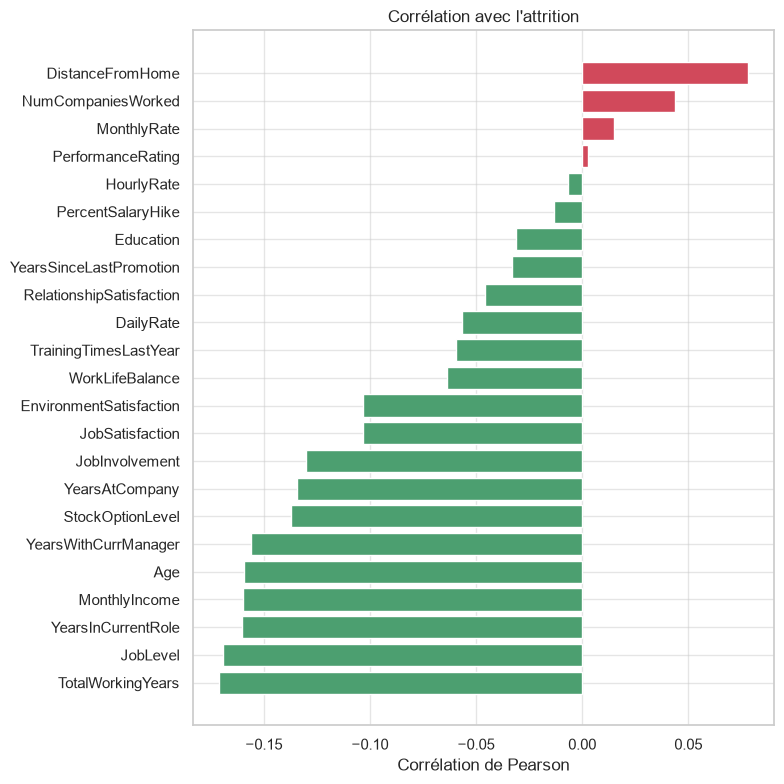

,var1,var2,corr
214,MonthlyIncome,JobLevel,0.950300
375,TotalWorkingYears,JobLevel,0.782208
311,PerformanceRating,PercentSalaryHike,0.773550
377,TotalWorkingYears,MonthlyIncome,0.772893
525,YearsWithCurrManager,YearsAtCompany,0.769212
479,YearsInCurrentRole,YearsAtCompany,0.758754
526,YearsWithCurrManager,YearsInCurrentRole,0.714365


In [5]:
# Cellule 3 : visualisations exploratoires

y_bin = (df["Attrition"] == "Yes").astype(int)
taux_global = y_bin.mean()

# 1) Taux d'attrition par variable catégorielle
cats = ["OverTime", "JobRole", "MaritalStatus", "BusinessTravel"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.ravel(), cats):
    t = (df.groupby(c)["Attrition"].apply(lambda s: (s == "Yes").mean() * 100)
           .sort_values(ascending=False).reset_index(name="taux"))
    sns.barplot(data=t, x="taux", y=c, color="#D1495B", ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
    ax.axvline(taux_global * 100, color="black", ls="--", lw=1,
               label=f"Moyenne ({taux_global*100:.1f}%)")
    ax.set_title(f"Taux d'attrition par {c}")
    ax.set_xlabel("Taux d'attrition (%)"); ax.set_ylabel("")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# 2) Distributions numériques selon la cible (histogramme + boxplot)
nums = ["MonthlyIncome", "Age", "YearsAtCompany"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, v in enumerate(nums):
    sns.histplot(data=df, x=v, hue="Attrition", palette=PALETTE, kde=True,
                 stat="density", common_norm=False, element="step", ax=axes[0, j])
    axes[0, j].set_title(f"Distribution de {v}")
    sns.boxplot(data=df, x="Attrition", y=v, hue="Attrition", palette=PALETTE,
                order=["No", "Yes"], legend=False, ax=axes[1, j])
plt.tight_layout(); plt.show()

# 3) Corrélations
num = df.select_dtypes("number").drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber"])
corr = num.corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Matrice de corrélation (variables numériques)")
plt.show()

# 4) Corrélation de chaque variable avec la cible
corr_cible = num.assign(Attrition=y_bin).corr()["Attrition"].drop("Attrition").sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
colors = ["#D1495B" if v > 0 else "#4C9F70" for v in corr_cible]
ax.barh(corr_cible.index, corr_cible.values, color=colors)
ax.set_title("Corrélation avec l'attrition"); ax.set_xlabel("Corrélation de Pearson")
plt.tight_layout(); plt.show()

# 5) Paires fortement corrélées (risque de redondance)
paires = (corr.where(~mask).stack().reset_index()
              .rename(columns={"level_0": "var1", "level_1": "var2", 0: "corr"}))
display(paires[paires["corr"].abs() > 0.7].sort_values("corr", ascending=False))

In [6]:
# Cellule 4 : préparation

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# ---------- Paramètres modifiables ----------
TARGET       = "Attrition"
POSITIVE     = "Yes"          # classe d'intérêt
TEST_SIZE    = 0.2
SEED         = 42
NUM_IMPUTE   = "median"       # "mean" | "median"
CAT_IMPUTE   = "most_frequent"
SCALE        = True           # normalisation des variables numériques
EXCLUDE      = []             # ex : ["Gender", "MaritalStatus"] pour tester l'équité
# --------------------------------------------

# Colonnes inutiles : constantes + identifiant
DROP = list(set(constantes + ["EmployeeNumber"] + EXCLUDE))
print("Colonnes retirées :", DROP)

data = df.drop(columns=DROP)
y = (data[TARGET] == POSITIVE).astype(int)
X = data.drop(columns=[TARGET])

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes("object").columns.tolist()
print(f"{len(num_cols)} variables numériques, {len(cat_cols)} catégorielles")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy=NUM_IMPUTE)),
                      ("sc", StandardScaler() if SCALE else "passthrough")]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy=CAT_IMPUTE)),
                      ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])

Xtr = preprocess.fit_transform(X_train)
Xte = preprocess.transform(X_test)
feat_names = [n.replace("num__", "").replace("cat__oh__", "").replace("cat__", "")
              for n in preprocess.get_feature_names_out()]
Xtr = pd.DataFrame(Xtr, columns=feat_names)
Xte = pd.DataFrame(Xte, columns=feat_names)

# Récapitulatif de la préparation
recap = pd.DataFrame({
    "Observations": [len(X_train), len(X_test)],
    "% classe positive": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Test"]).round(2)
display(recap)
print(f"Variables avant encodage : {X.shape[1]} | après encodage : {Xtr.shape[1]}")
print("Valeurs manquantes après traitement :", int(Xtr.isna().sum().sum()))

Colonnes retirées : ['Over18', 'StandardHours', 'EmployeeNumber', 'EmployeeCount']
23 variables numériques, 7 catégorielles


,Observations,% classe positive
Train,1176,16.16
Test,294,15.99


Variables avant encodage : 30 | après encodage : 51
Valeurs manquantes après traitement : 0


In [8]:
# Cellule 5 : entraînement (modèles + hyperparamètres)

import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score

# ---------- Choix depuis le notebook ----------
SELECTED  = ["Logistic Regression", "Decision Tree", "KNN", "Random Forest", "XGBoost"]
SCORING   = "roc_auc"
CV_FOLDS  = 3
# ----------------------------------------------

spw = (y_train == 0).sum() / (y_train == 1).sum()   # gestion du déséquilibre

configs = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                      {"max_depth": [3, 5, 8, 12, 15], "min_samples_leaf": [5, 20, 30]}),
    "KNN": (KNeighborsClassifier(), {"n_neighbors": [5, 11, 21, 31]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=SEED),
                      {"n_estimators": [200, 400, 600, 800], "max_depth": [5, 10, 15, 20]}),
    "XGBoost": (XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=SEED),
                {"n_estimators": [200, 400, 600, 800], "max_depth": [3, 5, 8, 12],
                 "learning_rate": [0.05, 0.1, 0.3, 0.6]}),
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
models, tuning = {}, []
for name in SELECTED:
    est, grid = configs[name]
    t0 = time.time()
    gs = GridSearchCV(est, grid, scoring=SCORING, cv=cv, n_jobs=-1)
    gs.fit(Xtr, y_train)
    models[name] = gs.best_estimator_
    tuning.append({"Modèle": name,
                   "Meilleurs hyperparamètres": gs.best_params_,
                   "AUC CV": round(gs.best_score_, 3),
                   "Temps (s)": round(time.time() - t0, 1)})
    print(f"✔ {name} terminé")

tuning = pd.DataFrame(tuning).set_index("Modèle")
pd.set_option("display.max_colwidth", None)
display(tuning)

✔ Logistic Regression terminé
✔ Decision Tree terminé
✔ KNN terminé
✔ Random Forest terminé
✔ XGBoost terminé


,Meilleurs hyperparamètres,AUC CV,Temps (s)
Modèle,,,
Logistic Regression,{'C': 0.1},0.828,12.8
Decision Tree,"{'max_depth': 8, 'min_samples_leaf': 30}",0.713,0.5
KNN,{'n_neighbors': 31},0.762,0.6
Random Forest,"{'max_depth': 20, 'n_estimators': 800}",0.799,21.6
XGBoost,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}",0.795,33.0


,Accuracy,Précision,Rappel,F1,AUC-ROC,PR-AUC,AUC train,Écart train-test
Logistic Regression,0.772,0.381,0.681,0.489,0.812,0.588,0.873,0.060
Random Forest,0.840,0.500,0.362,0.420,0.788,0.451,1.000,0.212
XGBoost,0.806,0.391,0.383,0.387,0.758,0.454,0.999,0.241
Decision Tree,0.714,0.324,0.723,0.447,0.709,0.350,0.862,0.153
KNN,0.847,1.000,0.043,0.082,0.700,0.355,0.838,0.138


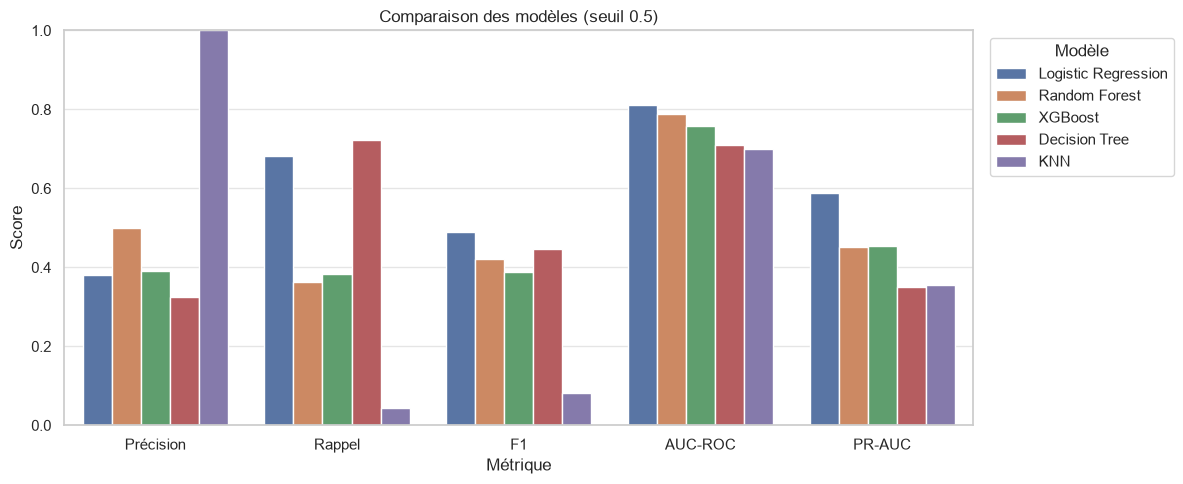

Meilleur modèle (AUC-ROC) : Logistic Regression


In [9]:
# Cellule 6 : tableau comparatif

from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

def evaluate(model, thr=0.5):
    p = model.predict_proba(Xte)[:, 1]
    pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_test, pred),
            "Précision": precision_score(y_test, pred, zero_division=0),
            "Rappel": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "AUC-ROC": roc_auc_score(y_test, p),
            "PR-AUC": average_precision_score(y_test, p)}

results = pd.DataFrame({n: evaluate(m) for n, m in models.items()}).T
results["AUC train"] = [roc_auc_score(y_train, m.predict_proba(Xtr)[:, 1]) for m in models.values()]
results["Écart train-test"] = results["AUC train"] - results["AUC-ROC"]   # surapprentissage
results = results.round(3).sort_values("AUC-ROC", ascending=False)

display(results.style
        .background_gradient(cmap="YlGnBu", subset=["Précision", "Rappel", "F1", "AUC-ROC", "PR-AUC"])
        .background_gradient(cmap="Reds", subset=["Écart train-test"])
        .format("{:.3f}"))

# Comparaison graphique
metrics = ["Précision", "Rappel", "F1", "AUC-ROC", "PR-AUC"]
long = results[metrics].reset_index().melt(id_vars="index", var_name="Métrique", value_name="Score")
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=long, x="Métrique", y="Score", hue="index", ax=ax)
ax.set_ylim(0, 1); ax.set_title("Comparaison des modèles (seuil 0.5)")
ax.legend(title="Modèle", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

best_name = results["AUC-ROC"].idxmax()
print(f"Meilleur modèle (AUC-ROC) : {best_name}")

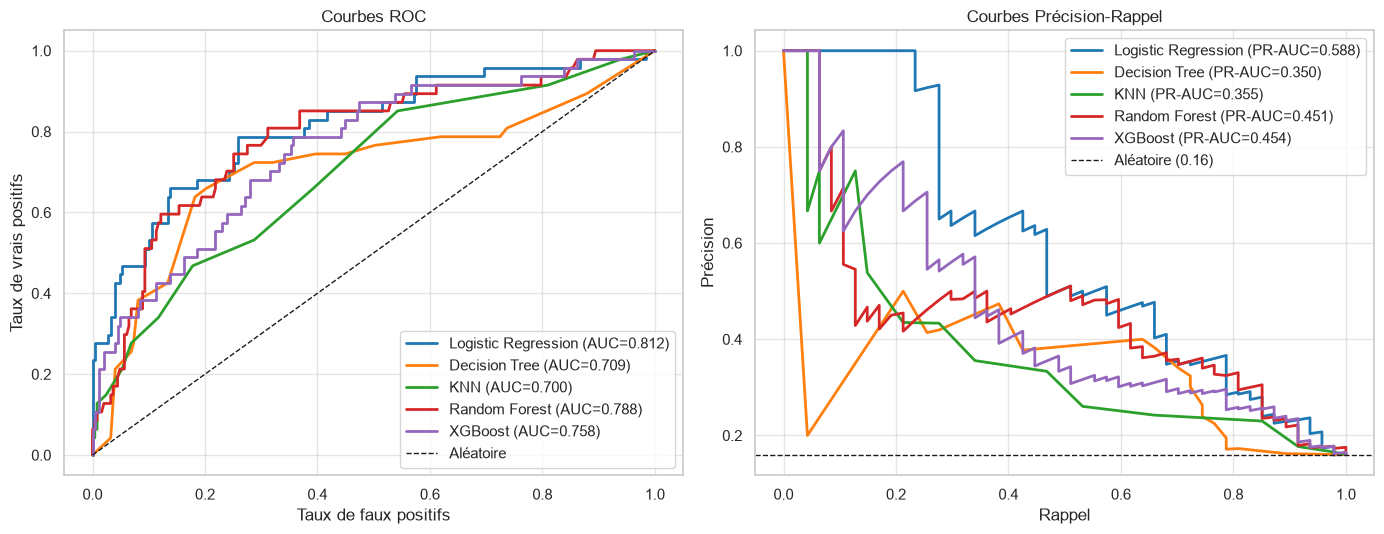

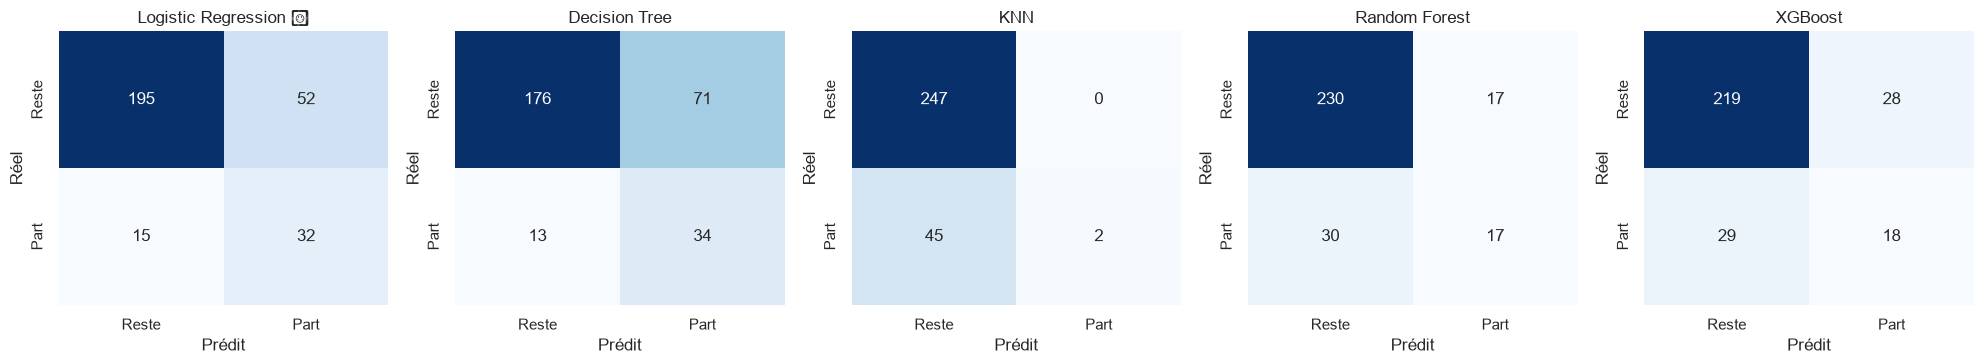

In [10]:
# Cellule 7 : courbes ROC, PR et matrice de confusion

colors = dict(zip(models, sns.color_palette("tab10", len(models))))
prevalence = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC superposées
for n, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(Xte)[:, 1])
    axes[0].plot(fpr, tpr, color=colors[n], lw=2, label=f"{n} (AUC={results.loc[n,'AUC-ROC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Aléatoire")
axes[0].set(title="Courbes ROC", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs")
axes[0].legend(loc="lower right")

# Précision-Rappel
for n, m in models.items():
    pr, rc, _ = precision_recall_curve(y_test, m.predict_proba(Xte)[:, 1])
    axes[1].plot(rc, pr, color=colors[n], lw=2, label=f"{n} (PR-AUC={results.loc[n,'PR-AUC']:.3f})")
axes[1].axhline(prevalence, color="k", ls="--", lw=1, label=f"Aléatoire ({prevalence:.2f})")
axes[1].set(title="Courbes Précision-Rappel", xlabel="Rappel", ylabel="Précision")
axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

# Matrices de confusion de tous les modèles (seuil 0.5)
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.8))
axes = np.atleast_1d(axes)
for ax, (n, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, (m.predict_proba(Xte)[:, 1] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Reste", "Part"], yticklabels=["Reste", "Part"])
    ax.set_title(n + (" ★" if n == best_name else ""))
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
plt.tight_layout(); plt.show()

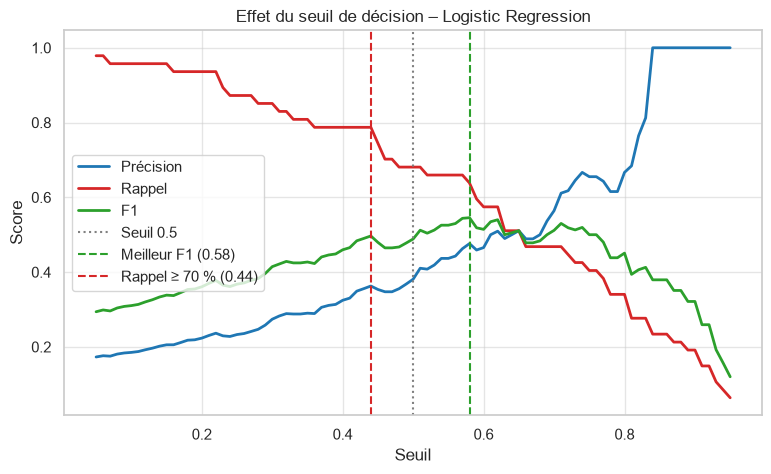

interactive(children=(Dropdown(description='model', options=('Logistic Regression', 'Decision Tree', 'KNN', 'R…

In [12]:
# Cellule 8 : seuil de décision

p_best = models[best_name].predict_proba(Xte)[:, 1]

# Balayage des seuils
seuils = np.arange(0.05, 0.96, 0.01)
sweep = pd.DataFrame({
    "seuil": seuils,
    "Précision": [precision_score(y_test, p_best >= t, zero_division=0) for t in seuils],
    "Rappel":    [recall_score(y_test, p_best >= t) for t in seuils],
    "F1":        [f1_score(y_test, p_best >= t) for t in seuils],
})
thr_f1 = sweep.loc[sweep["F1"].idxmax(), "seuil"]

# Seuil qui garantit un rappel >= 70 % avec la meilleure précision possible
ok = sweep[sweep["Rappel"] >= 0.70]
thr_rappel = ok.loc[ok["Précision"].idxmax(), "seuil"] if len(ok) else None

fig, ax = plt.subplots(figsize=(9, 5))
for col, c in zip(["Précision", "Rappel", "F1"], ["#1f77b4", "#d62728", "#2ca02c"]):
    ax.plot(sweep["seuil"], sweep[col], label=col, color=c, lw=2)
ax.axvline(0.5, color="gray", ls=":", label="Seuil 0.5")
ax.axvline(thr_f1, color="#2ca02c", ls="--", label=f"Meilleur F1 ({thr_f1:.2f})")
if thr_rappel is not None:
    ax.axvline(thr_rappel, color="#d62728", ls="--", label=f"Rappel ≥ 70 % ({thr_rappel:.2f})")
ax.set(title=f"Effet du seuil de décision – {best_name}", xlabel="Seuil", ylabel="Score")
ax.legend(); plt.show()

# Curseur interactif (pip install ipywidgets si besoin)
import ipywidgets as widgets

def show_threshold(model=best_name, seuil=0.5):
    p = models[model].predict_proba(Xte)[:, 1]
    pred = (p >= seuil).astype(int)
    pr_, rc_, f1_ = (precision_score(y_test, pred, zero_division=0),
                     recall_score(y_test, pred), f1_score(y_test, pred))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Reste", "Part"], yticklabels=["Reste", "Part"], ax=axes[0])
    axes[0].set(title=f"{model} – seuil {seuil:.2f}", xlabel="Prédit", ylabel="Réel")
    axes[1].bar(["Précision", "Rappel", "F1"], [pr_, rc_, f1_], color=["#1f77b4", "#d62728", "#2ca02c"])
    axes[1].set_ylim(0, 1)
    for i, v in enumerate([pr_, rc_, f1_]):
        axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center")
    axes[1].set_title(f"{pred.sum()} employés signalés sur {len(pred)}")
    plt.tight_layout(); plt.show()

widgets.interact(show_threshold,
                 model=widgets.Dropdown(options=list(models), value=best_name),
                 seuil=widgets.FloatSlider(min=0.05, max=0.95, step=0.01, value=0.5,
                                           continuous_update=False));

In [13]:
# Cellule 9 : export

import joblib, os

os.makedirs("artifacts", exist_ok=True)

# SHAP (arbre/linéaire) ne fonctionne pas avec KNN : on exporte alors XGBoost
EXPORT_NAME = best_name if best_name in ["Logistic Regression", "Decision Tree",
                                          "Random Forest", "XGBoost"] else "XGBoost"
export_model = models[EXPORT_NAME]
THRESHOLD = float(thr_f1)          # seuil retenu (cellule 8)

# Description des variables brutes (sert à valider les entrées et à construire le formulaire)
features_meta = []
for c in X.columns:
    if c in num_cols:
        features_meta.append({
            "name": c, "type": "numeric",
            "integer": bool((X[c].dropna() % 1 == 0).all()),
            "min": float(X[c].min()), "max": float(X[c].max()),
            "default": float(X[c].median())})
    else:
        features_meta.append({
            "name": c, "type": "categorical",
            "options": sorted(X[c].dropna().unique().tolist()),
            "default": X[c].mode()[0]})

metrics = {k: round(float(v), 3) for k, v in evaluate(export_model, THRESHOLD).items()}

bundle = {
    "model_name": EXPORT_NAME,
    "model": export_model,
    "preprocess": preprocess,
    "feat_names": list(feat_names),
    "features_meta": features_meta,
    "threshold": THRESHOLD,
    "metrics": metrics,
    "X_train_t": Xtr.values,                        # fond pour SHAP linéaire et LIME
    "X_test_t": Xte.values,
    "X_test_raw": X_test.reset_index(drop=True),    # pour "individu du jeu de test"
    "y_test": y_test.values,
}
joblib.dump(bundle, "artifacts/bundle.joblib", compress=3)
results.to_csv("artifacts/results.csv")
print("Export OK :", EXPORT_NAME, "| seuil =", round(THRESHOLD, 2), "|", metrics)

Export OK : Logistic Regression | seuil = 0.58 | {'Accuracy': 0.83, 'Précision': 0.476, 'Rappel': 0.638, 'F1': 0.545, 'AUC-ROC': 0.812, 'PR-AUC': 0.588}
